## Training a model to beat the baseline

We first need to prepare the data.

In [29]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("../res/MUD_malicious_urls_2026_V2.csv")
X = df.drop(columns=["label", "class_label", "type"])
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True, stratify=y)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessing = ColumnTransformer([("encoded", OneHotEncoder(sparse_output=False), ["reachability_class"]),
                                   ("delete", "drop", X.select_dtypes(include="str").columns)], remainder="passthrough", verbose_feature_names_out=False)
preprocessing.set_output(transform="pandas")
X_train_prep = preprocessing.fit_transform(X_train)
X_test_prep = preprocessing.transform(X_test)

After preparing the data, we will have to train our model so that it can learn to predict the different classes of malicious URLs in the dataset.

In [30]:
from sklearn.ensemble import HistGradientBoostingClassifier

model = HistGradientBoostingClassifier(random_state=42)
model.fit(X_train_prep, y_train)
print(model.score(X_test_prep, y_test))

0.9337278480512605


We got 93% accuracy in our first model! It's much better than the baseline model that scored 66.7%. But this model still uses the scheme-based features we found in the exploration, so let's check out how much of this score comes from that.

In [31]:
X_train_wout = X_train_prep.drop(columns=["abnormal_url", "//"])
X_test_wout = X_test_prep.drop(columns=["abnormal_url", "//"])

model.fit(X_train_wout, y_train)
print(model.score(X_test_wout, y_test))

0.9295088054736942


We can see that the model gets practically the same accuracy without these features. The model doesn't depend on these features. Now let's see how it does without the features that most correlate with the label of the URLs.

In [32]:
X_train_wout2 = X_train_prep.drop(columns=["abnormal_url", "//", "web_http_status", "phish_long_path"])
X_test_wout2 = X_test_prep.drop(columns=["abnormal_url", "//", "web_http_status", "phish_long_path"])

model.fit(X_train_wout2, y_train)
print(model.score(X_test_wout2, y_test))

0.9301645742638402


The model still gets 93% accuracy without the most correlated features, interesting finding. This usually happens because inside the data, the features that most correlate with the label are already contemplated partially in other features, so deleting these features doesn't affect the model's accuracy. Let's decompose the 93% accuracy.

In [33]:
from sklearn.metrics import classification_report
print(classification_report(y_test, model.predict(X_test_wout2)))

              precision    recall  f1-score   support

           0       0.93      0.98      0.96     84448
           1       0.96      0.98      0.97     19057
           2       0.88      0.64      0.74     18348
           3       0.96      0.89      0.93      4716

    accuracy                           0.93    126569
   macro avg       0.93      0.87      0.90    126569
weighted avg       0.93      0.93      0.93    126569



The model has a very good precision and recall with types 0, 1 and 3 URLs while type 2 (phishing) URLs seem to be the model's flaw. Let's take a deeper look.

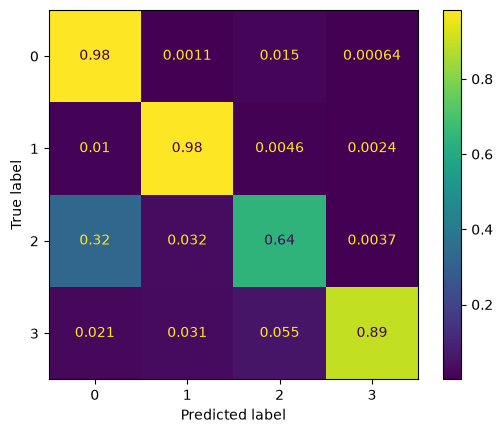

In [34]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test_wout2), normalize="true")

That's a real problem, the model misclassifies phishing URLs as benign URLs! Since phishing URLs are a real problem nowadays, let's set a threshold to reduce that misclassification.